## 신용위험 데이터

In [1]:
from pathlib import Path
from urllib.request import urlopen
import shutil

import pandas as pd
from IPython.display import display

DATA_DIR = Path("data")

In [2]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"  # 한글 폰트(Windows)
plt.rcParams["axes.unicode_minus"] = False

### UCI 신용위험 데이터

UCI Default of Credit Card Clients는 2005년 대만 카드 고객 30,000명의 기록이다. 고객별 신용한도와 4~9월의 상환 상태·청구액·납부액, 다음 달 연체 여부를 포함한다.

출처: [UCI Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients). 페이지의 `Variables Table`에는 변수 번호와 원래 이름이, `Additional Variable Information`에는 단위·범주 코드·기준 월이 설명되어 있다. DOI: 10.24432/C55S3H. 라이선스: CC BY 4.0.

### 항목 설명

CSV의 `X1`~`X23`은 원래 변수에 붙인 번호다. 금액·나이·상환 상태 등의 관측값을 담고 있다.

| CSV 열 | 원래 변수 이름 | 의미·단위 |
| --- | --- | --- |
| `ID` | `ID` | 고객 식별자 |
| `X1` | `LIMIT_BAL` | 부여된 신용한도, 대만 달러. 개인 및 가족의 부가 카드 신용을 포함한다. |
| `X2` | `SEX` | 성별 코드 |
| `X3` | `EDUCATION` | 교육 수준 코드 |
| `X4` | `MARRIAGE` | 혼인 상태 코드 |
| `X5` | `AGE` | 나이, 세 |
| `X6`~`X11` | `PAY_0`, `PAY_2`~`PAY_6` | 월별 상환 상태 코드 |
| `X12`~`X17` | `BILL_AMT1`~`BILL_AMT6` | 월별 청구액, 대만 달러 |
| `X18`~`X23` | `PAY_AMT1`~`PAY_AMT6` | 월별 납부액, 대만 달러 |
| `Y` | `default payment next month` | 다음 달 연체 여부. 0=없음, 1=있음. 예측할 정답이다. |

### 월별 기록의 대응

| 기준 월 | 상환 상태 | 청구액 | 납부액 |
| --- | --- | --- | --- |
| 2005년 9월 | `X6` (`PAY_0`) | `X12` (`BILL_AMT1`) | `X18` (`PAY_AMT1`) |
| 2005년 8월 | `X7` (`PAY_2`) | `X13` (`BILL_AMT2`) | `X19` (`PAY_AMT2`) |
| 2005년 7월 | `X8` (`PAY_3`) | `X14` (`BILL_AMT3`) | `X20` (`PAY_AMT3`) |
| 2005년 6월 | `X9` (`PAY_4`) | `X15` (`BILL_AMT4`) | `X21` (`PAY_AMT4`) |
| 2005년 5월 | `X10` (`PAY_5`) | `X16` (`BILL_AMT5`) | `X22` (`PAY_AMT5`) |
| 2005년 4월 | `X11` (`PAY_6`) | `X17` (`BILL_AMT6`) | `X23` (`PAY_AMT6`) |

### 범주 코드 설명

UCI의 `Additional Variable Information`에 명시된 범주 코드는 다음과 같다.

| 항목 | 공식 설명에 있는 코드 |
| --- | --- |
| 성별 `X2` | 1=남성, 2=여성 |
| 교육 수준 `X3` | 1=대학원, 2=대학교, 3=고등학교, 4=기타 |
| 혼인 상태 `X4` | 1=기혼, 2=미혼, 3=기타 |
| 상환 상태 `X6`~`X11` | -1=정상 납부, 1~8=각각 1~8개월 연체, 9=9개월 이상 연체 |

실제 CSV에는 공식 설명에 없는 교육 코드 `0·5·6`, 혼인 코드 `0`, 상환 상태 코드 `-2·0`도 있다. 의미를 확인할 때까지 해당 값은 원래 코드로 유지한다.

### 데이터 다운로드

UCI의 CSV를 `data/default_credit_clients.csv`에 저장한다.

In [3]:
CREDIT_URL = "https://archive.ics.uci.edu/static/public/350/data.csv"
credit_csv = DATA_DIR / "default_credit_clients.csv"

if not credit_csv.exists():
    temporary_path = credit_csv.with_suffix(".download")
    with urlopen(CREDIT_URL, timeout=60) as response:
        with temporary_path.open("wb") as output:
            shutil.copyfileobj(response, output)
    temporary_path.replace(credit_csv)

### 고객 데이터 불러오기

In [4]:
credit_df = pd.read_csv(credit_csv)

print("전체 행·열:", credit_df.shape)
display(credit_df.head(10))

전체 행·열: (30000, 25)


,ID,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
5,6,50000,1,1,2,37,0,0,0,0,...,19394,19619,20024,2500,1815,657,1000,1000,800,0
6,7,500000,1,1,2,29,0,0,0,0,...,542653,483003,473944,55000,40000,38000,20239,13750,13770,0
7,8,100000,2,2,2,23,0,-1,-1,0,...,221,-159,567,380,601,0,581,1687,1542,0
8,9,140000,2,3,1,28,0,0,2,0,...,12211,11793,3719,3329,0,432,1000,1000,1000,0
9,10,20000,1,3,2,35,-2,-2,-2,-2,...,0,13007,13912,0,0,0,13007,1122,0,0


---
## 1. 데이터 탐색

자료형·결측값·중복·정답 비율과 문서에 없는 범주 코드를 확인한다.

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# 원래 변수 이름으로 바꿔 읽기 쉽게 한다.
PAY_COLS = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
BILL_COLS = [f"BILL_AMT{i}" for i in range(1, 7)]
PAY_AMT_COLS = [f"PAY_AMT{i}" for i in range(1, 7)]
rename_map = dict(zip([f"X{i}" for i in range(1, 24)],
                      ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"] + PAY_COLS + BILL_COLS + PAY_AMT_COLS))
rename_map["Y"] = "default"
df = credit_df.rename(columns=rename_map)

print("자료형:", df.dtypes.value_counts().to_dict())
print("결측값 합계:", df.isna().sum().sum())
print("완전 중복 행:", df.duplicated().sum())
print("ID 제외 중복 행:", df.drop(columns="ID").duplicated().sum())
print("ID 고유 개수:", df.ID.nunique())
print("\n정답 비율")
print(df["default"].value_counts(normalize=True).round(4))

자료형: {dtype('int64'): 25}
결측값 합계: 0
완전 중복 행: 0
ID 제외 중복 행: 35
ID 고유 개수: 30000

정답 비율
default
0    0.7788
1    0.2212
Name: proportion, dtype: float64


In [6]:
# 문서에 없는 코드가 있는지 범주별 빈도를 본다.
for col in ["SEX", "EDUCATION", "MARRIAGE", "PAY_0"]:
    print(col, df[col].value_counts().sort_index().to_dict())

SEX {1: 11888, 2: 18112}
EDUCATION {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE {0: 54, 1: 13659, 2: 15964, 3: 323}
PAY_0 {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}


PAY_0,-2,-1,0,1,2,3,4,5,6,7,8
count,2759.000,5686.000,14737.000,3688.000,2667.000,322.000,76.000,26.0,11.000,9.000,19.000
mean,0.132,0.168,0.128,0.339,0.691,0.758,0.684,0.5,0.545,0.778,0.579


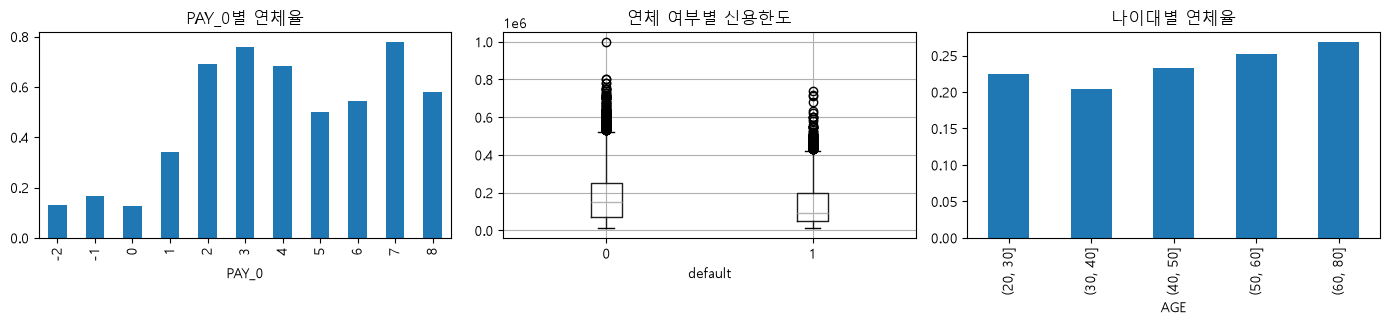

In [7]:
# 직전 달 상환 상태(PAY_0)별 연체율: 연체가 길수록 다음 달 연체율이 높다.
display(df.groupby("PAY_0")["default"].agg(["count", "mean"]).round(3).T)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
df.groupby("PAY_0")["default"].mean().plot.bar(ax=axes[0], title="PAY_0별 연체율")
df.boxplot(column="LIMIT_BAL", by="default", ax=axes[1])
axes[1].set_title("연체 여부별 신용한도"); fig.suptitle("")
df.groupby(pd.cut(df.AGE, [20, 30, 40, 50, 60, 80]), observed=True)["default"].mean().plot.bar(ax=axes[2], title="나이대별 연체율")
plt.tight_layout(); plt.show()

### 탐색 결과와 전처리 결정

- 30,000행·25열, 모두 정수형이고 결측값·완전 중복은 없다. ID를 빼면 같은 행이 35개 있지만 다른 고객일 수 있어 그대로 둔다.
- 연체(1) 비율은 약 22%로 불균형하다. 분할할 때 비율을 유지하고, 정확도 대신 PR-AUC·F1·재현율을 본다.
- 문서에 없는 코드: `EDUCATION` 0·5·6은 기타(4)로, `MARRIAGE` 0은 기타(3)로 합친다. 상환 상태 -2·0은 "연체 없음" 계열로 보고 순서형 숫자 그대로 쓴다.
- `SEX`·`EDUCATION`·`MARRIAGE`는 원-핫 인코딩, 나머지 숫자는 표준화한다. 기준은 학습 데이터에서만 구한다.
- `ID`는 식별용이라 입력에서 빼고, 사례 분석 때 고객을 가리키는 데 쓴다.

In [8]:
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})
print(df.EDUCATION.value_counts().sort_index().to_dict(), df.MARRIAGE.value_counts().sort_index().to_dict())

{1: 10585, 2: 14030, 3: 4917, 4: 468} {1: 13659, 2: 15964, 3: 377}


### 파생 변수

월별 기록을 요약한 변수를 만든다. 실험에서 기본 입력과 파생 입력을 비교한다.

| 변수 | 의미 |
| --- | --- |
| `PAY_MAX` | 6개월 중 가장 심한 상환 상태 |
| `PAY_LATE_CNT` | 연체(1 이상)한 개월 수 |
| `UTIL_1` | 9월 청구액 / 신용한도 (한도 소진율) |
| `PAY_RATIO_1` | 9월 납부액 / 8월 청구액 (전달 청구액 대비 납부 비율) |
| `BILL_MEAN`, `PAY_AMT_MEAN` | 6개월 평균 청구액·납부액 |

In [9]:
df["PAY_MAX"] = df[PAY_COLS].max(axis=1)
df["PAY_LATE_CNT"] = (df[PAY_COLS] > 0).sum(axis=1)
df["UTIL_1"] = df["BILL_AMT1"] / df["LIMIT_BAL"]
# 청구액이 0 이하이면 비율이 의미 없으므로 1(전액 납부)로 둔다.
df["PAY_RATIO_1"] = np.where(df["BILL_AMT2"] > 0, df["PAY_AMT1"] / df["BILL_AMT2"].clip(lower=1), 1.0).clip(0, 1)
df["BILL_MEAN"] = df[BILL_COLS].mean(axis=1)
df["PAY_AMT_MEAN"] = df[PAY_AMT_COLS].mean(axis=1)

ENG_COLS = ["PAY_MAX", "PAY_LATE_CNT", "UTIL_1", "PAY_RATIO_1", "BILL_MEAN", "PAY_AMT_MEAN"]
display(df[ENG_COLS + ["default"]].groupby("default").mean().round(3))

,PAY_MAX,PAY_LATE_CNT,UTIL_1,PAY_RATIO_1,BILL_MEAN,PAY_AMT_MEAN
default,,,,,,
0,0.201,0.504,0.405,0.427,45404.818,5828.237
1,1.274,1.996,0.490,0.317,43470.493,3328.216


## 2. 학습·검증·테스트 분할

- 비율: 학습 60% / 검증 20% / 테스트 20%
- 난수 시드: `SEED = 42`
- `stratify`로 세 데이터의 연체 비율을 유지한다.
- 모델·설정 선택은 검증 데이터로만 하고, 테스트는 최종 모델에 한 번만 쓴다.

In [10]:
from sklearn.model_selection import train_test_split

SEED = 42
CAT_COLS = ["SEX", "EDUCATION", "MARRIAGE"]
BASE_NUM_COLS = ["LIMIT_BAL", "AGE"] + PAY_COLS + BILL_COLS + PAY_AMT_COLS

train_df, temp_df = train_test_split(df, test_size=0.4, stratify=df["default"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["default"], random_state=SEED)

y_train, y_val, y_test = train_df["default"], val_df["default"], test_df["default"]
for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s} {len(part):6d}행  연체 비율 {part['default'].mean():.4f}")

train  18000행  연체 비율 0.2212
val     6000행  연체 비율 0.2212
test    6000행  연체 비율 0.2212


## 3. 전처리

`ColumnTransformer`로 범주는 원-핫, 숫자는 표준화한다. `fit`은 학습 데이터에만 하고 검증·테스트에는 `transform`만 한다.
모델과 묶어 `Pipeline`으로 만들면 이 규칙이 자동으로 지켜진다.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

def make_preprocessor(num_cols):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
        ("num", StandardScaler(), num_cols),
    ])

def feature_cols(use_eng):
    num_cols = BASE_NUM_COLS + (ENG_COLS if use_eng else [])
    return CAT_COLS + num_cols, num_cols

# 확인: 학습 데이터로 fit한 평균·표준편차를 검증 데이터에 그대로 적용하는지 본다.
cols, num_cols = feature_cols(use_eng=True)
prep = make_preprocessor(num_cols).fit(train_df[cols])
X_tr = prep.transform(train_df[cols]); X_va = prep.transform(val_df[cols])
print("변환 후 열 수:", X_tr.shape[1])
print("학습 표준화 평균(앞 3개):", X_tr[:, 9:12].mean(axis=0).round(3), "/ 검증:", X_va[:, 9:12].mean(axis=0).round(3))

변환 후 열 수: 35
학습 표준화 평균(앞 3개): [-0.  0. -0.] / 검증: [-0.016  0.009 -0.015]


## 4. 평가 함수

같은 검증 데이터에서 모든 모델을 비교한다.

- **ROC-AUC**: 순위 매기기 성능. 불균형에 덜 민감하지만 낙관적일 수 있다.
- **PR-AUC(Average Precision)**: 연체 클래스의 정밀도·재현율 균형. 주 지표로 쓴다.
- **정밀도·재현율·F1**: 임계값 0.5 기준과, 검증 데이터에서 F1이 최대가 되는 임계값 기준을 함께 본다.

In [12]:
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, precision_recall_curve, confusion_matrix)

def best_f1_threshold(y_true, proba):
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p * r / (p + r + 1e-12)
    i = np.argmax(f1[:-1])
    return t[i]

def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "ROC_AUC": roc_auc_score(y_true, proba),
        "PR_AUC": average_precision_score(y_true, proba),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "threshold": threshold,
    }

results = []      # 실험 기록
val_probas = {}   # PR 곡선용

def run(name, model, use_eng=True, note=""):
    cols, num_cols = feature_cols(use_eng)
    pipe = Pipeline([("prep", make_preprocessor(num_cols)), ("model", model)])
    pipe.fit(train_df[cols], y_train)
    proba = pipe.predict_proba(val_df[cols])[:, 1]
    r05 = evaluate(y_val, proba, 0.5)
    rbest = evaluate(y_val, proba, best_f1_threshold(y_val, proba))
    results.append({"실험": name, "파생변수": use_eng, "설정": note,
                    "ROC_AUC": r05["ROC_AUC"], "PR_AUC": r05["PR_AUC"],
                    "P@0.5": r05["precision"], "R@0.5": r05["recall"], "F1@0.5": r05["F1"],
                    "best_thr": rbest["threshold"], "F1@best": rbest["F1"]})
    val_probas[name] = proba
    return pipe

# 확인: 무작위에 가까운 예측이면 ROC-AUC가 0.5 근처, PR-AUC가 양성 비율 근처여야 한다.
rng = np.random.default_rng(SEED)
sanity = evaluate(y_val, rng.random(len(y_val)))
print({k: round(v, 3) for k, v in sanity.items()}, "양성 비율:", round(y_val.mean(), 3))
assert abs(sanity["ROC_AUC"] - 0.5) < 0.03 and abs(sanity["PR_AUC"] - y_val.mean()) < 0.03

{'ROC_AUC': 0.502, 'PR_AUC': 0.225, 'precision': 0.224, 'recall': 0.497, 'F1': 0.308, 'threshold': 0.5} 양성 비율: 0.221


## 5. 모델 비교

| 모델 | 특징 | 적용 이유 |
| --- | --- | --- |
| Dummy | 다수 클래스 비율만 예측 | 기준선 |
| 로지스틱 회귀 | 선형, 계수로 해석 가능 | 신용평가의 전통적 기준 모델 |
| 랜덤 포레스트 | 트리 배깅, 비선형·상호작용 | 튜닝이 적어도 안정적 |
| XGBoost | 그래디언트 부스팅, 규제 | 표 데이터에서 강한 성능 |
| LightGBM | 히스토그램 부스팅, 빠름 | 표 데이터에서 강한 성능·빠른 실험 |
| MLP | 다층 신경망(딥러닝) | 트리 계열과 비교 |

먼저 기본 설정으로 비교하고, 그다음 설정을 바꿔 실험한다.

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

run("Dummy", DummyClassifier(strategy="prior"))
run("LogReg", LogisticRegression(max_iter=1000), note="C=1")
run("RandomForest", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    note="300 trees, leaf=5")
run("XGBoost", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=SEED, n_jobs=-1),
    note="300, lr=0.05, depth=4")
run("LightGBM", LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=SEED, verbose=-1),
    note="300, lr=0.05, leaves=31")
run("MLP", MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True, max_iter=300, random_state=SEED),
    note="(64,32), alpha=1e-3")

pd.DataFrame(results).round(4)

,실험,파생변수,설정,ROC_AUC,PR_AUC,P@0.5,R@0.5,F1@0.5,best_thr,F1@best
0,Dummy,True,,0.5000,0.2212,0.0000,0.0000,0.0000,0.2212,0.3622
1,LogReg,True,C=1,0.7411,0.4925,0.6390,0.2788,0.3882,0.2920,0.5148
2,RandomForest,True,"300 trees, leaf=5",0.7723,0.5294,0.6419,0.3323,0.4379,0.3035,0.5382
3,XGBoost,True,"300, lr=0.05, depth=4",0.7750,0.5370,0.6490,0.3331,0.4402,0.2780,0.5387
4,LightGBM,True,"300, lr=0.05, leaves=31",0.7719,0.5338,0.6513,0.3308,0.4388,0.3088,0.5333
5,MLP,True,"(64,32), alpha=1e-3",0.7657,0.5243,0.6426,0.3225,0.4295,0.2978,0.5363


## 6. 하이퍼파라미터·설정 실험

바꿔 본 설정:

1. 파생 변수 사용 여부 (LogReg, LightGBM)
2. 클래스 가중치 `class_weight="balanced"` / `scale_pos_weight`
3. LightGBM: 트리 수·학습률·`num_leaves`·규제
4. XGBoost: `max_depth`
5. MLP: 은닉층 크기
6. 로지스틱 회귀: 규제 강도 `C`

In [14]:
# 1) 파생 변수 끄기
run("LogReg-noEng", LogisticRegression(max_iter=1000), use_eng=False, note="C=1")
run("LightGBM-noEng", LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=SEED, verbose=-1),
    use_eng=False, note="300, lr=0.05, leaves=31")

# 2) 클래스 가중치
run("LogReg-balanced", LogisticRegression(max_iter=1000, class_weight="balanced"), note="C=1, balanced")
run("LightGBM-balanced", LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, class_weight="balanced",
                                        random_state=SEED, verbose=-1), note="300, lr=0.05, leaves=31, balanced")
run("XGBoost-spw", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, scale_pos_weight=3.5,
                                 random_state=SEED, n_jobs=-1), note="300, lr=0.05, depth=4, spw=3.5")

# 3) LightGBM 설정
for n, lr, leaves, mcs in [(200, 0.03, 15, 50), (500, 0.02, 15, 100), (1000, 0.01, 15, 100), (300, 0.1, 63, 20)]:
    run(f"LightGBM-{n}-{lr}-{leaves}-{mcs}",
        LGBMClassifier(n_estimators=n, learning_rate=lr, num_leaves=leaves, min_child_samples=mcs,
                       subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1),
        note=f"{n}, lr={lr}, leaves={leaves}, min_child={mcs}, sub/col=0.8")

# 4) XGBoost 깊이
for depth in [2, 3, 6]:
    run(f"XGBoost-d{depth}", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=depth, subsample=0.8,
                                           colsample_bytree=0.8, random_state=SEED, n_jobs=-1),
        note=f"300, lr=0.05, depth={depth}, sub/col=0.8")

# 5) MLP 크기
for hidden in [(32,), (128, 64, 32)]:
    run(f"MLP-{hidden}", MLPClassifier(hidden_layer_sizes=hidden, alpha=1e-3, early_stopping=True, max_iter=300,
                                       random_state=SEED), note=f"{hidden}, alpha=1e-3")

# 6) 로지스틱 회귀 규제
for c in [0.01, 100]:
    run(f"LogReg-C{c}", LogisticRegression(max_iter=1000, C=c), note=f"C={c}")

result_df = pd.DataFrame(results).round(4)
result_df.sort_values("PR_AUC", ascending=False)

,실험,파생변수,설정,ROC_AUC,PR_AUC,P@0.5,R@0.5,F1@0.5,best_thr,F1@best
16,XGBoost-d3,True,"300, lr=0.05, depth=3, sub/col=0.8",0.7797,0.5455,0.6539,0.3346,0.4427,0.2756,0.5375
11,LightGBM-200-0.03-15-50,True,"200, lr=0.03, leaves=15, min_child=50, sub/col...",0.7809,0.5452,0.6496,0.3255,0.4337,0.2378,0.5343
12,LightGBM-500-0.02-15-100,True,"500, lr=0.02, leaves=15, min_child=100, sub/co...",0.7791,0.5450,0.6533,0.3308,0.4392,0.2976,0.5400
10,XGBoost-spw,True,"300, lr=0.05, depth=4, spw=3.5",0.7752,0.5445,0.4622,0.6074,0.5249,0.5265,0.5329
13,LightGBM-1000-0.01-15-100,True,"1000, lr=0.01, leaves=15, min_child=100, sub/c...",0.7791,0.5429,0.6490,0.3331,0.4402,0.3107,0.5383
15,XGBoost-d2,True,"300, lr=0.05, depth=2, sub/col=0.8",0.7797,0.5423,0.6652,0.3338,0.4446,0.3007,0.5358
9,LightGBM-balanced,True,"300, lr=0.05, leaves=31, balanced",0.7719,0.5392,0.4768,0.5878,0.5265,0.6046,0.5319
3,XGBoost,True,"300, lr=0.05, depth=4",0.7750,0.5370,0.6490,0.3331,0.4402,0.2780,0.5387
17,XGBoost-d6,True,"300, lr=0.05, depth=6, sub/col=0.8",0.7713,0.5350,0.6456,0.3391,0.4447,0.2860,0.5280
4,LightGBM,True,"300, lr=0.05, leaves=31",0.7719,0.5338,0.6513,0.3308,0.4388,0.3088,0.5333


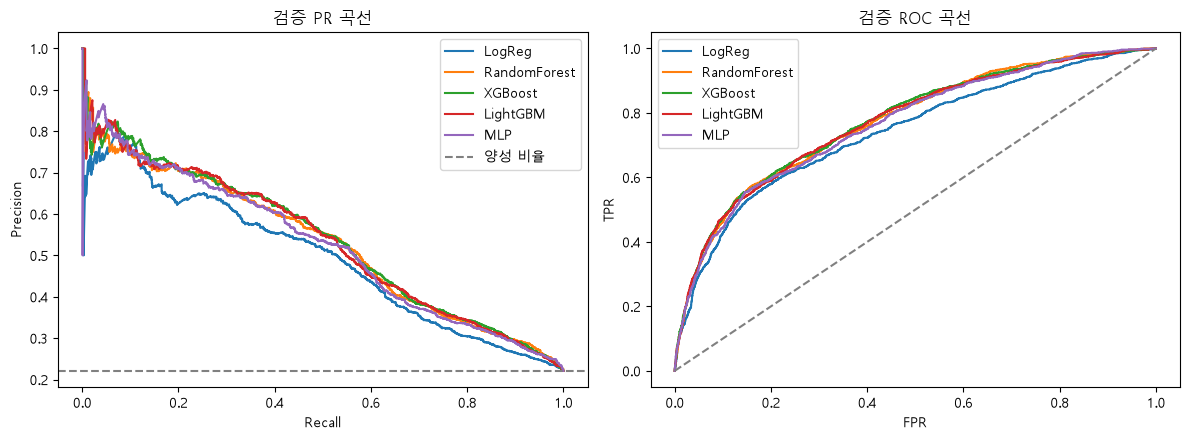

In [15]:
# 검증 데이터 PR 곡선: 모델별 대표 설정
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
from sklearn.metrics import roc_curve
for name in ["LogReg", "RandomForest", "XGBoost", "LightGBM", "MLP"]:
    p, r, _ = precision_recall_curve(y_val, val_probas[name])
    ax[0].plot(r, p, label=name)
    fpr, tpr, _ = roc_curve(y_val, val_probas[name])
    ax[1].plot(fpr, tpr, label=name)
ax[0].axhline(y_val.mean(), ls="--", c="gray", label="양성 비율")
ax[0].set(xlabel="Recall", ylabel="Precision", title="검증 PR 곡선"); ax[0].legend()
ax[1].plot([0, 1], [0, 1], ls="--", c="gray")
ax[1].set(xlabel="FPR", ylabel="TPR", title="검증 ROC 곡선"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. 최종 모델 선택

검증 PR-AUC가 가장 높은 설정을 고르고, 임계값도 검증 데이터에서 F1이 최대인 값으로 정한다.
테스트 데이터는 이 선택이 끝난 뒤 한 번만 평가한다.

In [16]:
best_row = result_df.sort_values("PR_AUC", ascending=False).iloc[0]
print("최종 후보:", best_row["실험"], "/", best_row["설정"])
print(best_row[["ROC_AUC", "PR_AUC", "F1@0.5", "best_thr", "F1@best"]])

최종 후보: XGBoost-d3 / 300, lr=0.05, depth=3, sub/col=0.8
ROC_AUC     0.7797
PR_AUC      0.5455
F1@0.5      0.4427
best_thr    0.2756
F1@best     0.5375
Name: 16, dtype: object


In [17]:
# 최종 설정으로 학습 데이터에 다시 학습하고(검증 때와 같은 학습 데이터), 테스트에서 평가한다.
FINAL_NAME = best_row["실험"]
FINAL_THRESHOLD = float(best_row["best_thr"])
FINAL_MODEL = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
                            colsample_bytree=0.8, random_state=SEED, n_jobs=-1)
assert FINAL_NAME == "XGBoost-d3", "검증 1위 설정이 바뀌면 FINAL_MODEL도 맞춰 바꾼다."

cols, num_cols = feature_cols(use_eng=True)
final_pipe = Pipeline([("prep", make_preprocessor(num_cols)), ("model", FINAL_MODEL)]).fit(train_df[cols], y_train)

# 확인: 다시 학습한 모델의 검증 점수가 실험 기록과 같아야 한다(재현성).
val_proba_final = final_pipe.predict_proba(val_df[cols])[:, 1]
assert abs(average_precision_score(y_val, val_proba_final) - best_row["PR_AUC"]) < 1e-3

test_proba = final_pipe.predict_proba(test_df[cols])[:, 1]
test_res = {"임계값 0.5": evaluate(y_test, test_proba, 0.5),
            f"임계값 {FINAL_THRESHOLD:.3f}(검증 F1 최대)": evaluate(y_test, test_proba, FINAL_THRESHOLD)}
pd.DataFrame(test_res).T.round(4)

,ROC_AUC,PR_AUC,precision,recall,F1,threshold
임계값 0.5,0.7907,0.5764,0.7015,0.3595,0.4753,0.5000
임계값 0.276(검증 F1 최대),0.7907,0.5764,0.5256,0.5795,0.5513,0.2756


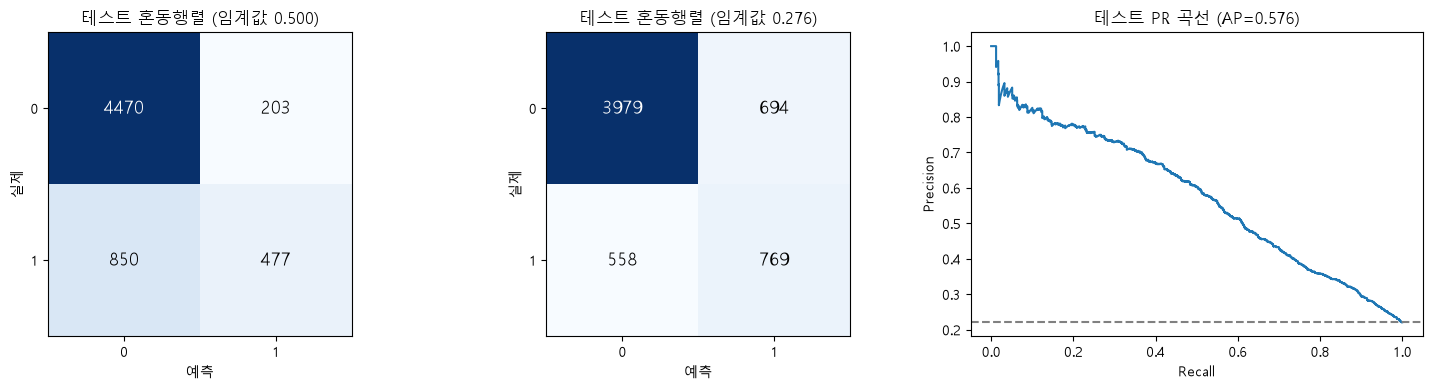

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, thr in zip(ax[:2], [0.5, FINAL_THRESHOLD]):
    cm = confusion_matrix(y_test, (test_proba >= thr).astype(int))
    a.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        a.text(j, i, v, ha="center", va="center", fontsize=13, color="white" if v > cm.max() / 2 else "black")
    a.set(xticks=[0, 1], yticks=[0, 1], xlabel="예측", ylabel="실제", title=f"테스트 혼동행렬 (임계값 {thr:.3f})")
p, r, t = precision_recall_curve(y_test, test_proba)
ax[2].plot(r, p); ax[2].axhline(y_test.mean(), ls="--", c="gray")
ax[2].set(xlabel="Recall", ylabel="Precision", title=f"테스트 PR 곡선 (AP={average_precision_score(y_test, test_proba):.3f})")
plt.tight_layout(); plt.show()

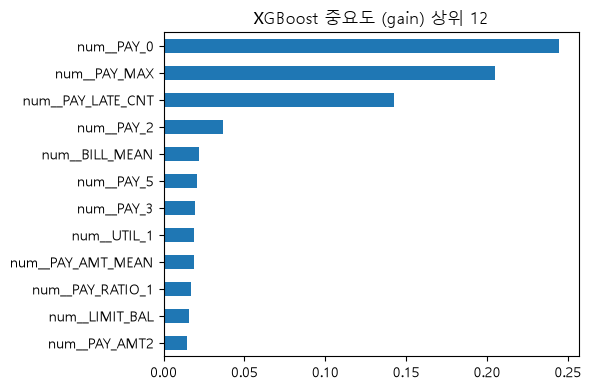

num__PAY_0           0.245
num__PAY_MAX         0.205
num__PAY_LATE_CNT    0.143
num__PAY_2           0.037
num__BILL_MEAN       0.022
num__PAY_5           0.021
num__PAY_3           0.019
num__UTIL_1          0.019
dtype: float32


In [19]:
# 변수 중요도(XGBoost 기본: 분할 이득 gain)
feat_names = final_pipe.named_steps["prep"].get_feature_names_out()
imp = pd.Series(final_pipe.named_steps["model"].feature_importances_, index=feat_names)
imp.sort_values().tail(12).plot.barh(figsize=(6, 4), title="XGBoost 중요도 (gain) 상위 12")
plt.tight_layout(); plt.show()
print(imp.sort_values(ascending=False).head(8).round(3))

## 8. 예측 사례 분석

테스트 데이터에서 확신을 갖고 맞힌 사례와 크게 틀린 사례를 본다. `ID`로 고객을 가리킨다.

In [20]:
case = test_df[["ID", "LIMIT_BAL", "AGE", "PAY_0", "PAY_2", "PAY_MAX", "PAY_LATE_CNT", "UTIL_1", "PAY_RATIO_1", "default"]].copy()
case["proba"] = test_proba.round(3)
case["pred"] = (test_proba >= FINAL_THRESHOLD).astype(int)

show = {
    "맞힌 연체 (TP, 확률 높은 순)": case[(case.pred == 1) & (case.default == 1)].nlargest(5, "proba"),
    "맞힌 정상 (TN, 확률 낮은 순)": case[(case.pred == 0) & (case.default == 0)].nsmallest(5, "proba"),
    "놓친 연체 (FN, 확률 낮은 순)": case[(case.pred == 0) & (case.default == 1)].nsmallest(5, "proba"),
    "잘못 경보 (FP, 확률 높은 순)": case[(case.pred == 1) & (case.default == 0)].nlargest(5, "proba"),
}
for title, part in show.items():
    print(title); display(part)

맞힌 연체 (TP, 확률 높은 순)


,ID,LIMIT_BAL,AGE,PAY_0,PAY_2,PAY_MAX,PAY_LATE_CNT,UTIL_1,PAY_RATIO_1,default,proba,pred
17862,17863,10000,26,3,2,7,6,0.240000,0.0,1,0.887,1
13406,13407,10000,23,2,2,7,6,0.240000,0.0,1,0.882,1
25053,25054,500000,55,3,2,3,6,0.009914,0.0,1,0.881,1
20721,20722,20000,37,3,2,7,6,0.120000,0.0,1,0.879,1
17950,17951,200000,43,2,3,3,6,0.472645,0.0,1,0.878,1


맞힌 정상 (TN, 확률 낮은 순)


,ID,LIMIT_BAL,AGE,PAY_0,PAY_2,PAY_MAX,PAY_LATE_CNT,UTIL_1,PAY_RATIO_1,default,proba,pred
260,261,510000,29,0,0,0,0,0.153590,0.402458,0,0.017,0
29847,29848,310000,46,-1,-1,-1,0,0.049777,1.000000,0,0.019,0
22888,22889,400000,37,0,0,0,0,0.123618,0.501832,0,0.020,0
9681,9682,460000,36,-1,-1,0,0,0.126765,1.000000,0,0.020,0
28805,28806,390000,45,0,0,0,0,0.473197,0.036954,0,0.021,0


놓친 연체 (FN, 확률 낮은 순)


,ID,LIMIT_BAL,AGE,PAY_0,PAY_2,PAY_MAX,PAY_LATE_CNT,UTIL_1,PAY_RATIO_1,default,proba,pred
10732,10733,260000,32,0,0,0,0,0.652823,0.039047,1,0.022,0
28993,28994,480000,39,0,0,0,0,0.205352,0.099569,1,0.026,0
16276,16277,300000,31,0,0,0,0,0.115050,0.494234,1,0.028,0
982,983,500000,36,-2,-2,-2,0,0.090212,1.000000,1,0.029,0
22262,22263,420000,31,0,0,0,0,0.555745,0.049689,1,0.032,0


잘못 경보 (FP, 확률 높은 순)


,ID,LIMIT_BAL,AGE,PAY_0,PAY_2,PAY_MAX,PAY_LATE_CNT,UTIL_1,PAY_RATIO_1,default,proba,pred
9671,9672,170000,48,2,2,7,6,0.014118,0.000000,0,0.849,1
3018,3019,20000,34,2,0,2,4,0.304950,0.264585,0,0.827,1
10533,10534,10000,52,2,2,2,6,0.347500,0.251947,0,0.826,1
292,293,30000,43,3,2,3,6,0.056667,0.421456,0,0.823,1
7692,7693,230000,45,2,2,2,4,0.963874,0.044112,0,0.823,1


In [21]:
# 유형별 평균: 놓친 연체(FN)는 상환 기록상 정상 고객(TN)과 구분이 어렵다.
case["유형"] = np.select([(case.pred == 1) & (case.default == 1), (case.pred == 0) & (case.default == 0),
                         (case.pred == 0) & (case.default == 1)], ["TP", "TN", "FN"], "FP")
display(case.groupby("유형")[["LIMIT_BAL", "AGE", "PAY_0", "PAY_MAX", "PAY_LATE_CNT", "UTIL_1", "PAY_RATIO_1", "proba"]]
        .mean().round(3).assign(건수=case["유형"].value_counts()))

,LIMIT_BAL,AGE,PAY_0,PAY_MAX,PAY_LATE_CNT,UTIL_1,PAY_RATIO_1,proba,건수
유형,,,,,,,,,
FN,160555.556,36.643,-0.405,-0.065,0.222,0.410,0.502,0.153,558
FP,107146.974,35.445,0.791,1.954,2.494,0.495,0.295,0.449,694
TN,191432.521,35.462,-0.394,-0.091,0.150,0.380,0.455,0.119,3979
TP,112002.601,36.092,1.479,2.261,3.325,0.538,0.196,0.580,769


## 9. 추가 실험: 월별 추세 변수 + 5-fold 교차 검증

사례 분석에서 놓친 연체(FN)는 과거 연체 기록이 없는 고객이었다. 6개월 기록을 평균·최댓값으로만 요약해서
"점점 나빠지는 중"이라는 신호를 놓쳤을 수 있다. 그래서 **추세 변수**를 추가한다.

또 상위 모델 차이(0.003 이내)가 검증 세트 하나의 우연인지 보려고 **학습 데이터 안에서 5-fold 교차 검증**으로 평균·표준편차를 구한다.
테스트 데이터는 쓰지 않는다.

| 추가 변수 | 의미 |
| --- | --- |
| `BILL_SLOPE`, `PAY_AMT_SLOPE` | 6개월 청구액·납부액의 기울기 / 신용한도 (최근으로 갈수록 늘면 양수) |
| `PAY_SLOPE` | 상환 상태의 기울기 (최근으로 갈수록 나빠지면 양수) |
| `PAY_RECENT_MINUS_OLD` | 최근 3개월 평균 상환 상태 − 이전 3개월 평균 |
| `UTIL_2`~`UTIL_6`, `UTIL_MAX` | 월별 한도 소진율과 최댓값 |
| `PAY_RATIO_2`~`PAY_RATIO_5`, `PAY_RATIO_MEAN` | 월별 전달 청구액 대비 납부 비율과 평균 |
| `ZERO_PAY_CNT` | 납부액이 0인 개월 수 |

In [22]:
def slope(d, cols):
    # cols는 최근(9월)→과거(4월) 순서. 최근으로 갈수록 값이 커지면 양수가 되도록 x를 뒤집는다.
    x = -(np.arange(6) - 2.5)
    return (d[cols].to_numpy(float) * x).sum(axis=1) / (x ** 2).sum()

def add_trend(d):
    d = d.copy()
    d["BILL_SLOPE"] = slope(d, BILL_COLS) / d["LIMIT_BAL"]
    d["PAY_AMT_SLOPE"] = slope(d, PAY_AMT_COLS) / d["LIMIT_BAL"]
    d["PAY_SLOPE"] = slope(d, PAY_COLS)
    d["PAY_RECENT_MINUS_OLD"] = d[PAY_COLS[:3]].mean(axis=1) - d[PAY_COLS[3:]].mean(axis=1)
    for i in range(2, 7):
        d[f"UTIL_{i}"] = d[f"BILL_AMT{i}"] / d["LIMIT_BAL"]
    for i in range(2, 6):
        d[f"PAY_RATIO_{i}"] = np.where(d[f"BILL_AMT{i+1}"] > 0,
                                       d[f"PAY_AMT{i}"] / d[f"BILL_AMT{i+1}"].clip(lower=1), 1.0).clip(0, 1)
    d["UTIL_MAX"] = d[[f"UTIL_{i}" for i in range(1, 7)]].max(axis=1)
    d["PAY_RATIO_MEAN"] = d[[f"PAY_RATIO_{i}" for i in range(1, 6)]].mean(axis=1)
    d["ZERO_PAY_CNT"] = (d[PAY_AMT_COLS] == 0).sum(axis=1)
    return d

TREND_COLS = (["BILL_SLOPE", "PAY_AMT_SLOPE", "PAY_SLOPE", "PAY_RECENT_MINUS_OLD"]
              + [f"UTIL_{i}" for i in range(2, 7)] + [f"PAY_RATIO_{i}" for i in range(2, 6)]
              + ["UTIL_MAX", "PAY_RATIO_MEAN", "ZERO_PAY_CNT"])

# 확인: 최근으로 갈수록 청구액이 늘면 기울기가 양수, 상환 상태가 최근에 나빠지면 PAY_SLOPE가 양수여야 한다.
toy = pd.DataFrame([[600, 500, 400, 300, 200, 100]], columns=BILL_COLS)
assert slope(toy, BILL_COLS)[0] > 0
toy_pay = pd.DataFrame([[2, 1, 0, 0, -1, -1]], columns=PAY_COLS)
assert slope(toy_pay, PAY_COLS)[0] > 0

train_t, val_t = add_trend(train_df), add_trend(val_df)
display(train_t[TREND_COLS + ["default"]].groupby("default").mean().T.round(3))

default,0,1
BILL_SLOPE,0.023,0.020
PAY_AMT_SLOPE,0.003,0.001
PAY_SLOPE,0.038,0.108
PAY_RECENT_MINUS_OLD,0.112,0.320
UTIL_2,0.389,0.491
UTIL_3,0.370,0.474
UTIL_4,0.336,0.444
UTIL_5,0.310,0.416
UTIL_6,0.294,0.404
PAY_RATIO_2,0.438,0.318


In [23]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_models = {
    "LogReg": lambda: LogisticRegression(max_iter=2000),
    "XGBoost-d3": lambda: XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
                                        colsample_bytree=0.8, random_state=SEED, n_jobs=-1),
    "LightGBM-500-0.02-15-100": lambda: LGBMClassifier(n_estimators=500, learning_rate=0.02, num_leaves=15,
                                                       min_child_samples=100, subsample=0.8, subsample_freq=1,
                                                       colsample_bytree=0.8, random_state=SEED, verbose=-1),
}
feature_sets = {"기본+파생": [], "기본+파생+추세": TREND_COLS}

cv_rows, fold_scores = [], {}
for fs_name, extra in feature_sets.items():
    num_cols = BASE_NUM_COLS + ENG_COLS + extra
    cols = CAT_COLS + num_cols
    for m_name, make in cv_models.items():
        pipe = Pipeline([("prep", make_preprocessor(num_cols)), ("model", make())])
        # 학습 데이터 18,000행만 5개로 나눠 교차 검증한다. 전처리도 fold마다 학습 fold에서만 fit된다.
        scores = cross_validate(pipe, train_t[cols], y_train, cv=cv, scoring=["average_precision", "roc_auc"])
        pipe.fit(train_t[cols], y_train)
        val_ap = average_precision_score(y_val, pipe.predict_proba(val_t[cols])[:, 1])
        fold_scores[(fs_name, m_name)] = scores["test_average_precision"]
        cv_rows.append({"입력": fs_name, "모델": m_name, "열 수": len(cols),
                        "CV PR_AUC 평균": scores["test_average_precision"].mean(),
                        "CV PR_AUC 표준편차": scores["test_average_precision"].std(),
                        "CV ROC_AUC 평균": scores["test_roc_auc"].mean(),
                        "검증 PR_AUC": val_ap})

cv_df = pd.DataFrame(cv_rows).round(4)
cv_df.sort_values("CV PR_AUC 평균", ascending=False)

,입력,모델,열 수,CV PR_AUC 평균,CV PR_AUC 표준편차,CV ROC_AUC 평균,검증 PR_AUC
5,기본+파생+추세,LightGBM-500-0.02-15-100,45,0.5620,0.0101,0.7871,0.5461
2,기본+파생,LightGBM-500-0.02-15-100,29,0.5602,0.0136,0.7850,0.5450
4,기본+파생+추세,XGBoost-d3,45,0.5598,0.0115,0.7868,0.5505
1,기본+파생,XGBoost-d3,29,0.5577,0.0154,0.7853,0.5455
3,기본+파생+추세,LogReg,45,0.5141,0.0125,0.7586,0.4946
0,기본+파생,LogReg,29,0.5137,0.0115,0.7580,0.4925


In [24]:
# 같은 fold끼리 짝지어 비교: 추세 변수를 넣었을 때 fold별로 얼마나 바뀌는지 본다.
paired = pd.DataFrame({
    m: fold_scores[("기본+파생+추세", m)] - fold_scores[("기본+파생", m)] for m in cv_models
}, index=[f"fold{i+1}" for i in range(5)])
display(paired.round(4))
print("평균 변화:", paired.mean().round(4).to_dict())
print("좋아진 fold 수:", (paired > 0).sum().to_dict())

# 모델 간 비교도 같은 fold끼리: XGBoost-d3 vs LightGBM (기본+파생)
diff = fold_scores[("기본+파생", "LightGBM-500-0.02-15-100")] - fold_scores[("기본+파생", "XGBoost-d3")]
print("LightGBM − XGBoost fold별 차이:", diff.round(4), "평균", round(diff.mean(), 4))

,LogReg,XGBoost-d3,LightGBM-500-0.02-15-100
fold1,0.0012,-0.0052,-0.0021
fold2,0.0001,0.0021,0.0026
fold3,-0.0018,0.0107,0.0014
fold4,0.0047,0.0082,0.0139
fold5,-0.0021,-0.0055,-0.0069


평균 변화: {'LogReg': 0.0004, 'XGBoost-d3': 0.0021, 'LightGBM-500-0.02-15-100': 0.0018}
좋아진 fold 수: {'LogReg': 3, 'XGBoost-d3': 3, 'LightGBM-500-0.02-15-100': 3}
LightGBM − XGBoost fold별 차이: [-0.0006  0.0012  0.0082  0.003   0.0005] 평균 0.0025


In [25]:
# 추세 변수를 넣은 XGBoost-d3의 중요도: 추세 변수가 실제로 쓰였는지 본다.
num_cols = BASE_NUM_COLS + ENG_COLS + TREND_COLS
trend_pipe = Pipeline([("prep", make_preprocessor(num_cols)), ("model", cv_models["XGBoost-d3"]())])
trend_pipe.fit(train_t[CAT_COLS + num_cols], y_train)
imp_t = pd.Series(trend_pipe.named_steps["model"].feature_importances_,
                  index=trend_pipe.named_steps["prep"].get_feature_names_out()).sort_values(ascending=False)
print(imp_t.head(10).round(3))
print("\n추세 변수 중요도 합계:", round(imp_t[[f"num__{c}" for c in TREND_COLS]].sum(), 3))

num__PAY_MAX         0.211
num__PAY_0           0.193
num__PAY_LATE_CNT    0.109
num__PAY_2           0.033
num__UTIL_MAX        0.018
num__PAY_3           0.017
num__UTIL_2          0.017
num__BILL_MEAN       0.017
num__ZERO_PAY_CNT    0.016
num__PAY_AMT_MEAN    0.015
dtype: float32

추세 변수 중요도 합계: 0.162


### 추가 실험 결론

- 추세 변수를 넣으면 CV PR-AUC 평균이 LogReg +0.0004, XGBoost +0.0021, LightGBM +0.0018 오른다. 하지만 세 모델 모두 5개 fold 중 3개에서만 좋아졌고, 변화가 fold 간 표준편차(약 0.01~0.015)보다 훨씬 작아 **의미 있는 개선으로 보기 어렵다**.
- 추세 변수는 정상·연체 평균이 확실히 다르고(예: `PAY_RECENT_MINUS_OLD` 0.11 vs 0.32), 모델 중요도 합도 0.16으로 실제로 쓰인다. 그런데도 점수가 거의 안 오르는 것은 상환 상태 변수(`PAY_0`, `PAY_MAX`, `PAY_LATE_CNT`)와 **같은 정보를 다른 모양으로 담고 있어서**다.
- LightGBM은 XGBoost-d3보다 5개 fold 중 4개에서 앞섰지만 평균 차이는 +0.0025로 표준편차보다 작다. 검증 세트 하나로 고른 1위(XGBoost-d3)와 순서가 바뀌는 것도 이 정도 차이는 우연으로 뒤집힌다는 뜻이다.
- 그래서 **최종 모델(XGBoost-d3, 추세 변수 없음)을 바꾸지 않는다.** 바꿀 근거가 노이즈 범위이고, 이미 한 번 본 테스트 데이터로 다시 고르면 테스트가 선택에 새어 들어가기 때문이다. 테스트는 다시 평가하지 않았다.

## 10. 정리

- 최종 모델과 근거, 테스트 결과, 사례 분석 해석, 추가 실험, 한계·개선 방향은 `실험기록.md`에 정리했다.
- 이 노트북은 새 커널에서 처음부터 끝까지 실행해 확인했다.